In [ ]:
from google.colab import files
upload = files.upload()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import glob

# Find uploaded CSV file
files = glob.glob('/content/*.csv')
print(files)

# Load the CSV file
df = pd.read_csv(files[-1])

# Check dataset
print("Dataset loaded successfully!")
print(df.head())

['/content/Retail_Sales_2025_Synthetic (1) (2).csv', '/content/Retail_Sales_2025_Synthetic (1).csv', '/content/Retail_Sales_2025_Synthetic (1) (1).csv']
Dataset loaded successfully!
    Order_ID  Order_Date Region        Category     Product Customer_Segment  \
0  ORD-00190  2025-01-01  North         Fashion     T-Shirt         Consumer   
1  ORD-00432  2025-01-01   West  Home & Kitchen       Mixer         Consumer   
2  ORD-01142  2025-01-01  North     Electronics  Headphones         Consumer   
3  ORD-00836  2025-01-01   East         Fashion      Jacket        Corporate   
4  ORD-00326  2025-01-01  North  Home & Kitchen    Cookware   Small Business   

  Sales_Channel  Units  Unit_Price  Discount_Pct  Revenue      Cost   Profit  \
0   Marketplace      1         899          0.10    809.1    449.50   359.60   
1        Online      4        4499          0.00  17996.0  12597.20  5398.80   
2        Online      3        2400          0.15   6120.0   4896.00  1224.00   
3   Marketplace  

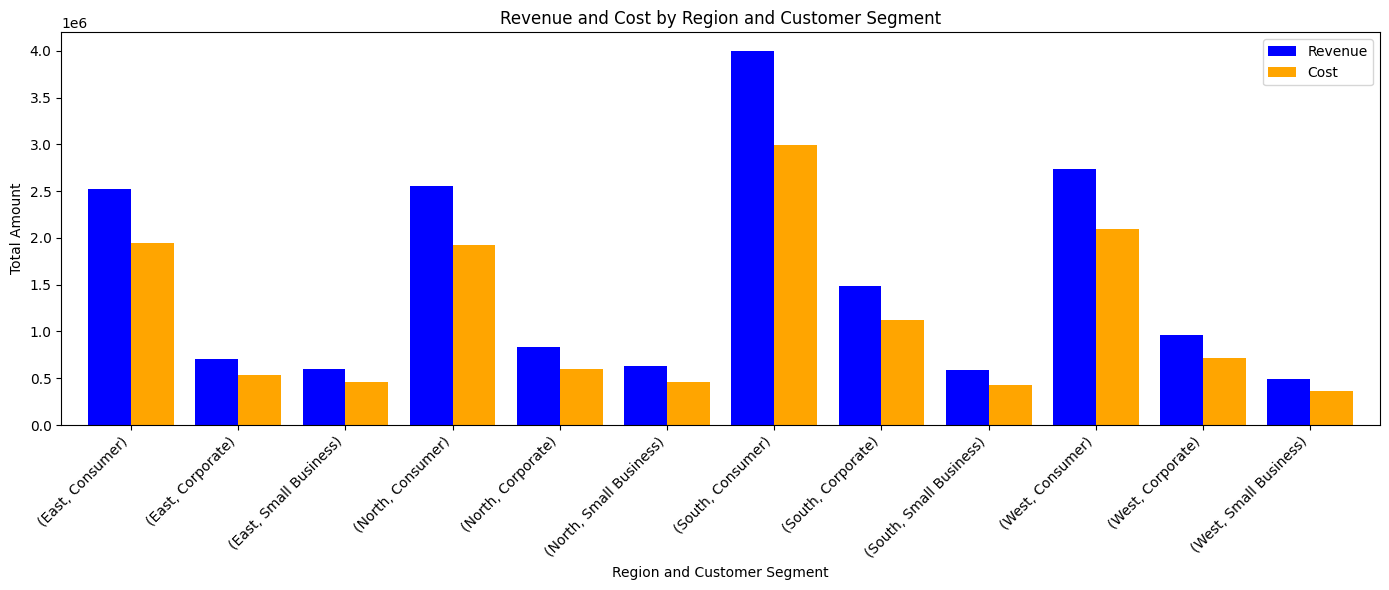

In [ ]:
import matplotlib.pyplot as plt

sales_data = df.groupby(
    ['Region', 'Customer_Segment']
)[['Revenue', 'Cost']].sum()

ax = sales_data.plot(
    kind='bar',
    figsize=(14, 6),
    color=['blue', 'orange'],
    width=0.8
)

plt.title('Revenue and Cost by Region and Customer Segment')
plt.xlabel('Region and Customer Segment')
plt.ylabel('Total Amount')
plt.xticks(rotation=45, ha='right')
plt.legend(['Revenue', 'Cost'])
plt.tight_layout()

plt.show()

In [ ]:
print("REGION-WISE REVENUE")
print(df.groupby('Region')['Revenue'].sum().sort_values(ascending=False))

print("\nCUSTOMER-WISE REVENUE")
print(df.groupby('Customer_Segment')['Revenue'].sum().sort_values(ascending=False))

REGION-WISE REVENUE
Region
South    6076463.65
West     4192295.50
North    4021872.60
East     3828083.30
Name: Revenue, dtype: float64

CUSTOMER-WISE REVENUE
Customer_Segment
Consumer          11811163.55
Corporate          3987412.25
Small Business     2320139.25
Name: Revenue, dtype: float64


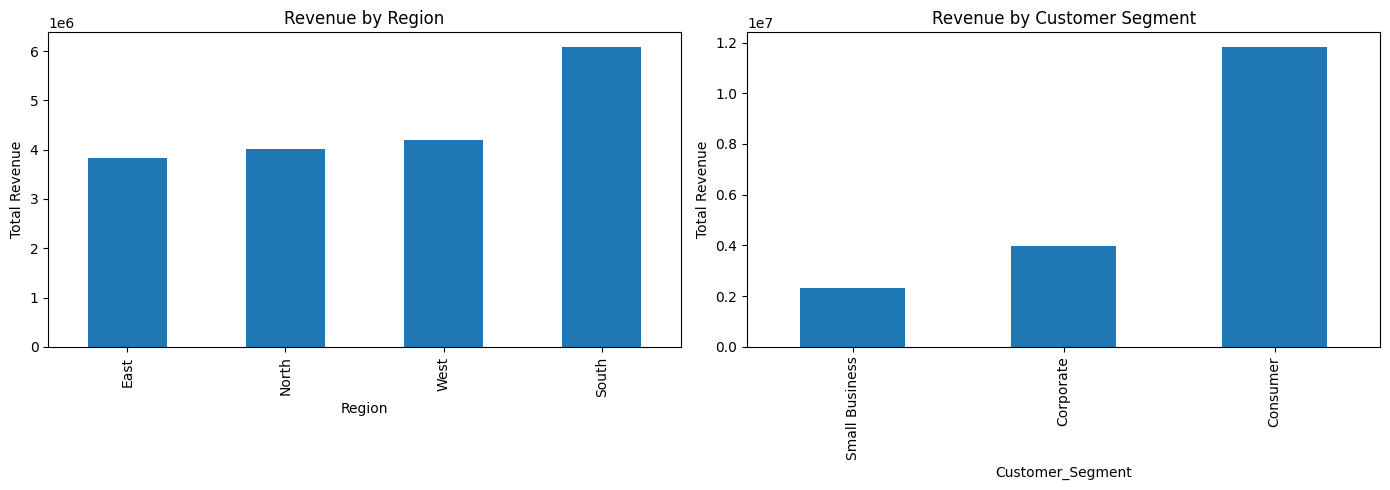

In [ ]:
import matplotlib.pyplot as plt

region = df.groupby('Region')['Revenue'].sum().sort_values()

customer = df.groupby('Customer_Segment')['Revenue'].sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Region graph
region.plot(kind='bar', ax=axes[0])
axes[0].set_title('Revenue by Region')
axes[0].set_ylabel('Total Revenue')

# Customer graph
customer.plot(kind='bar', ax=axes[1])
axes[1].set_title('Revenue by Customer Segment')
axes[1].set_ylabel('Total Revenue')

plt.tight_layout()
plt.show()

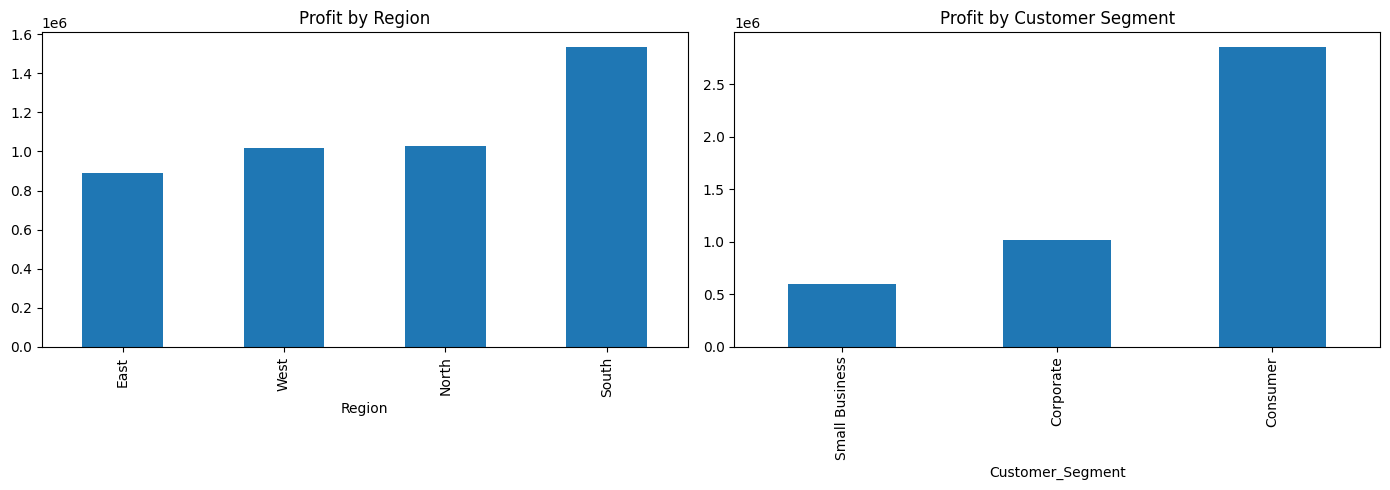

Region-wise Profit:
Region
South    1533053.03
North    1025587.56
West     1017645.54
East      890034.86
Name: Profit, dtype: float64

Customer-wise Profit:
Customer_Segment
Consumer          2850280.21
Corporate         1015553.51
Small Business     600487.27
Name: Profit, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Profit by Region
region_profit = df.groupby('Region')['Profit'].sum().sort_values()

region_profit.plot(
    kind='bar',
    ax=axes[0],
    title='Profit by Region'
)

# Profit by Customer
customer_profit = df.groupby('Customer_Segment')['Profit'].sum().sort_values()

customer_profit.plot(
    kind='bar',
    ax=axes[1],
    title='Profit by Customer Segment'
)

plt.tight_layout()
plt.show()

print("Region-wise Profit:")
print(region_profit.sort_values(ascending=False))

print("\nCustomer-wise Profit:")
print(customer_profit.sort_values(ascending=False))

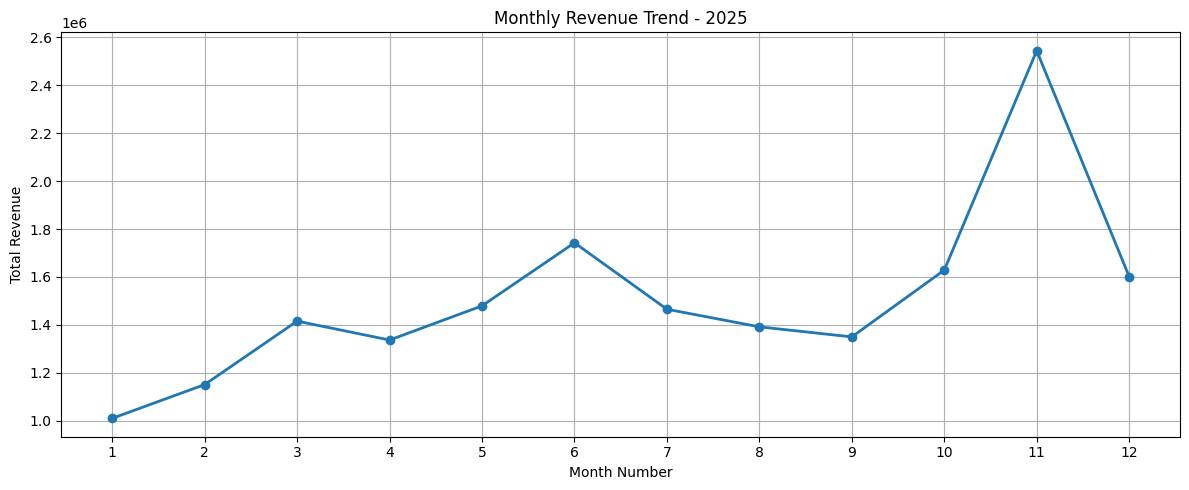

In [ ]:
import matplotlib.pyplot as plt

monthly_revenue = df.groupby('Month_Num')['Revenue'].sum()

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Revenue Trend - 2025')
plt.xlabel('Month Number')
plt.ylabel('Total Revenue')
plt.xticks(range(1, 13))
plt.grid(True)

plt.tight_layout()
plt.show()

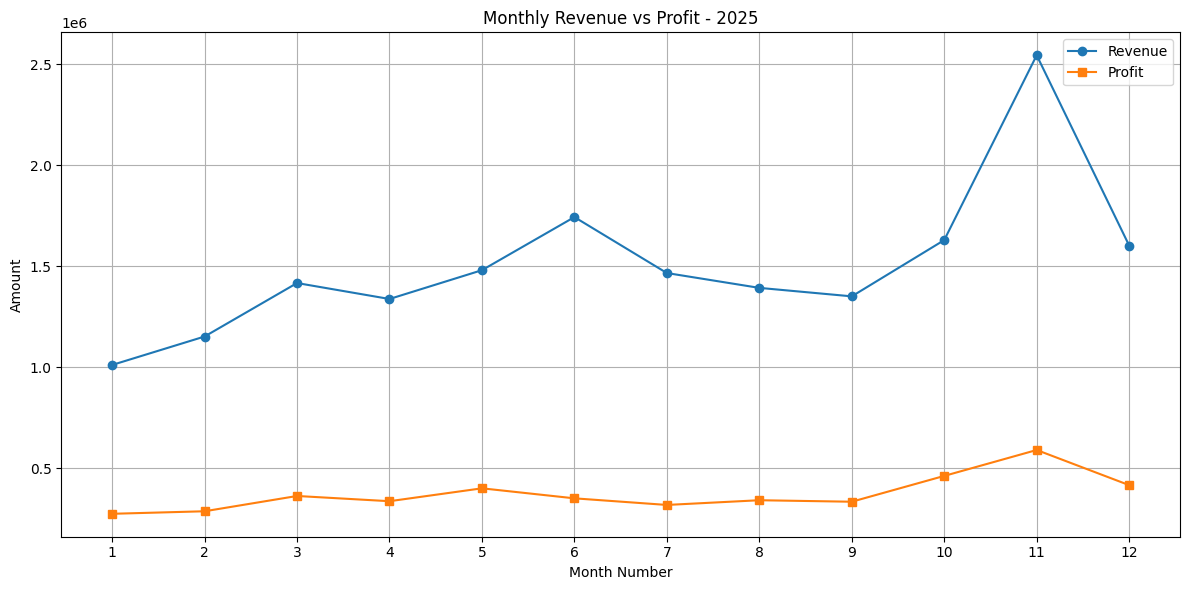

In [ ]:
import matplotlib.pyplot as plt

monthly = df.groupby('Month_Num')[['Revenue', 'Profit']].sum()

plt.figure(figsize=(12, 6))

plt.plot(monthly.index, monthly['Revenue'],
         marker='o', label='Revenue')

plt.plot(monthly.index, monthly['Profit'],
         marker='s', label='Profit')

plt.title('Monthly Revenue vs Profit - 2025')
plt.xlabel('Month Number')
plt.ylabel('Amount')
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

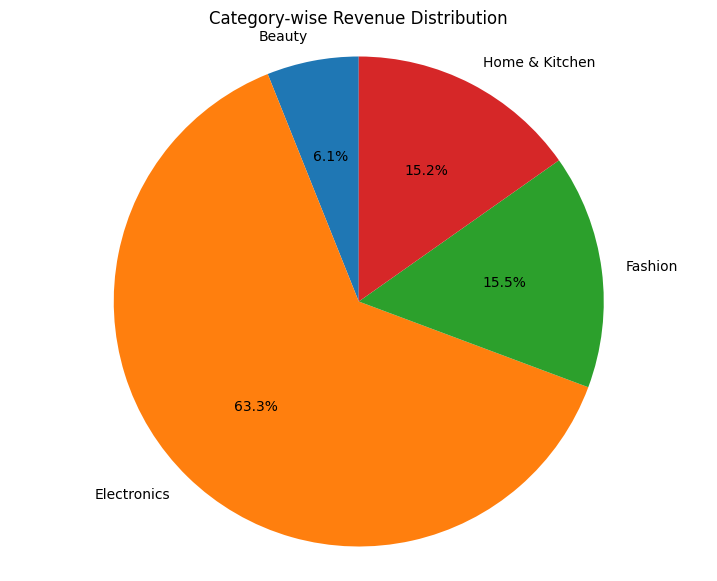

Category
Electronics       11460200.00
Fashion            2802243.05
Home & Kitchen     2758373.40
Beauty             1097898.60
Name: Revenue, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

category_sales = df.groupby('Category')['Revenue'].sum()

plt.figure(figsize=(9, 7))

plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Category-wise Revenue Distribution')
plt.axis('equal')

plt.show()

print(category_sales.sort_values(ascending=False))

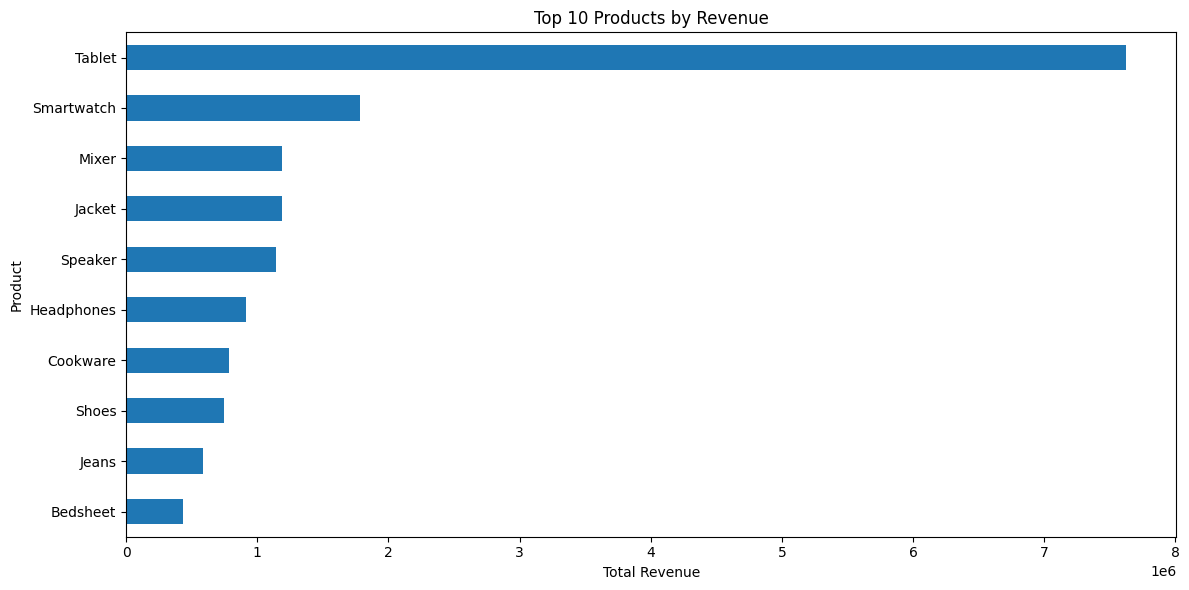

Product
Tablet        7624775.00
Smartwatch    1780625.00
Mixer         1190435.40
Jacket        1187035.75
Speaker       1141120.00
Headphones     913680.00
Cookware       780641.10
Shoes          745133.30
Jeans          583562.70
Bedsheet       436047.30
Name: Revenue, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

product_sales = (
    df.groupby('Product')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

product_sales.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

print(product_sales)

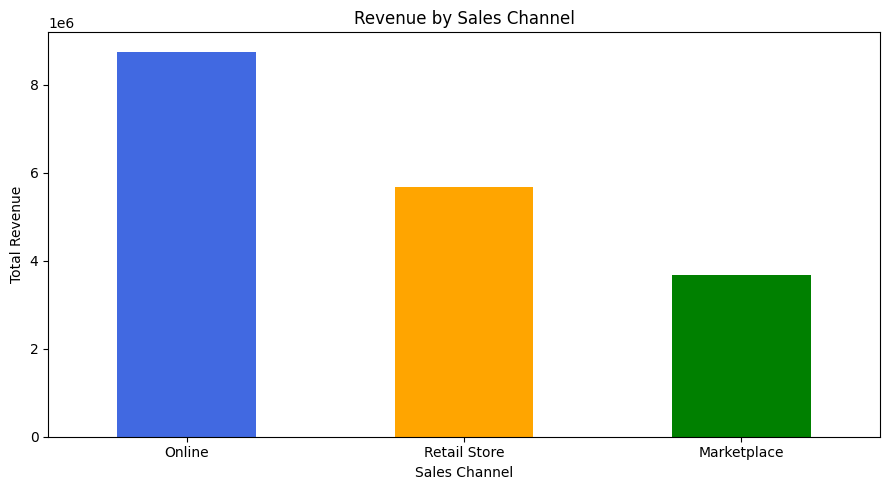

Sales_Channel
Online          8759582.15
Retail Store    5684452.50
Marketplace     3674680.40
Name: Revenue, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

channel_sales = df.groupby('Sales_Channel')['Revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

channel_sales.plot(
    kind='bar',
    color=['royalblue', 'orange', 'green']
)

plt.title('Revenue by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

print(channel_sales)

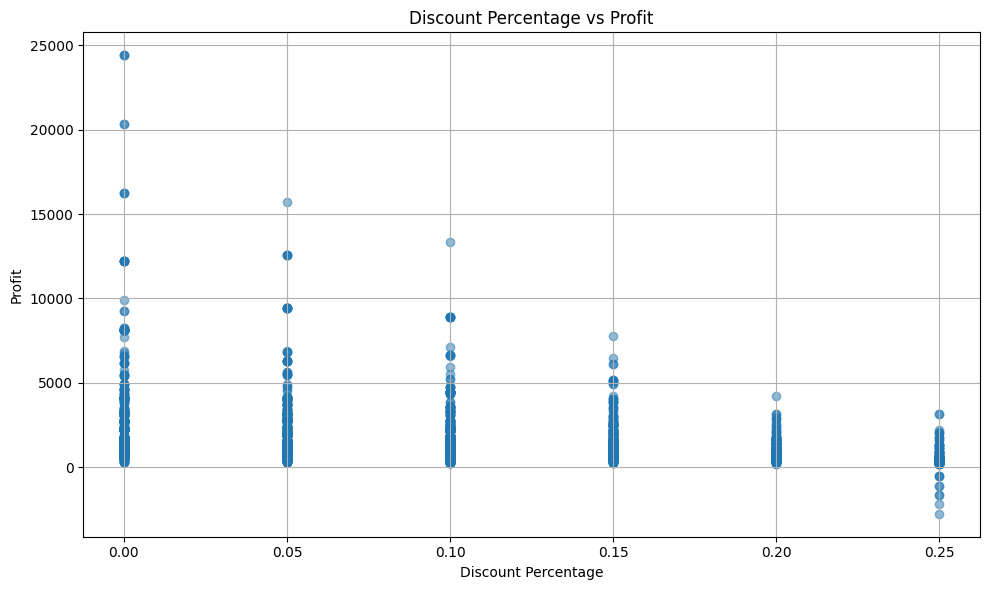

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df['Discount_Pct'],
    df['Profit'],
    alpha=0.5
)

plt.title('Discount Percentage vs Profit')
plt.xlabel('Discount Percentage')
plt.ylabel('Profit')

plt.grid(True)
plt.tight_layout()
plt.show()

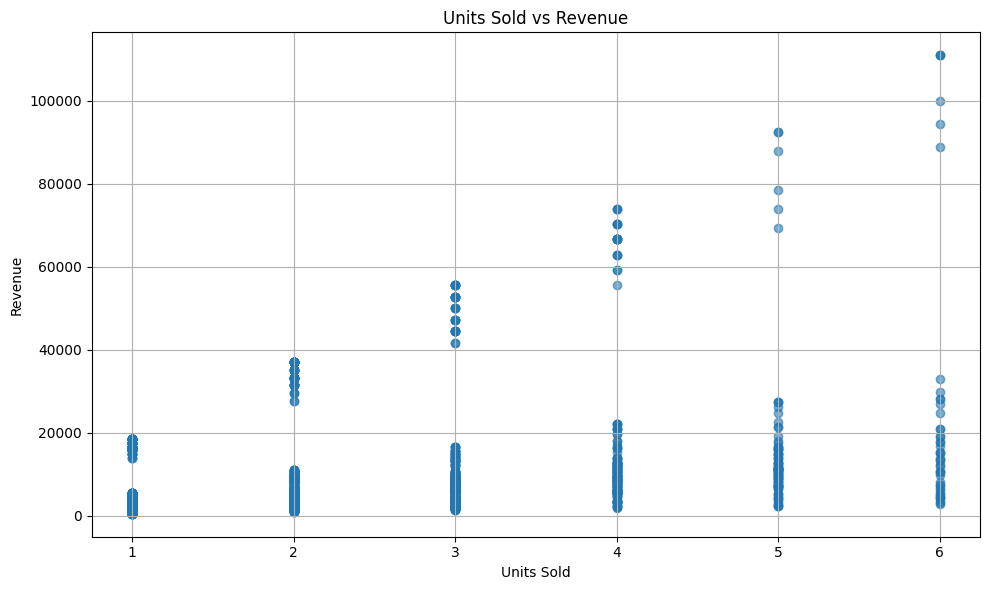

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(df['Units'], df['Revenue'], alpha=0.6)

plt.title('Units Sold vs Revenue')
plt.xlabel('Units Sold')
plt.ylabel('Revenue')

plt.grid(True)
plt.tight_layout()
plt.show()

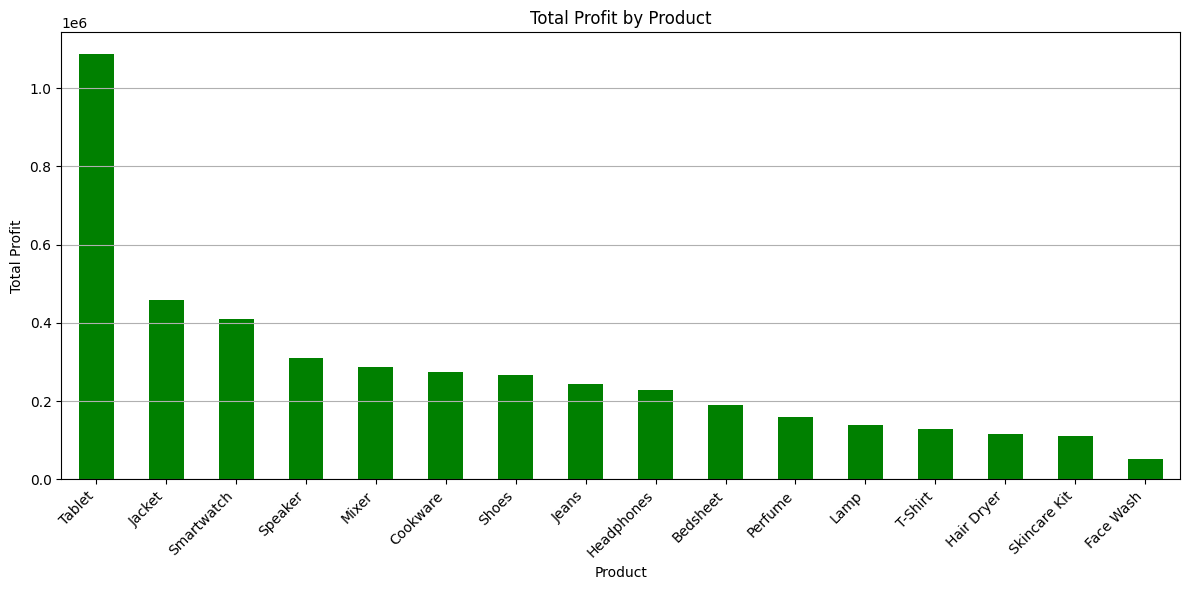

Product
Tablet          1087985.00
Jacket           458124.07
Smartwatch       410025.00
Speaker          311104.00
Mixer            286586.30
Cookware         275309.64
Shoes            267281.16
Jeans            244382.31
Headphones       228240.00
Bedsheet         190584.81
Perfume          158497.15
Lamp             139057.95
T-Shirt          129186.30
Hair Dryer       116481.03
Skincare Kit     110926.00
Face Wash         52550.27
Name: Profit, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

product_profit = df.groupby('Product')['Profit'].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

product_profit.plot(kind='bar', color='green')

plt.title('Total Profit by Product')
plt.xlabel('Product')
plt.ylabel('Total Profit')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

print(product_profit)

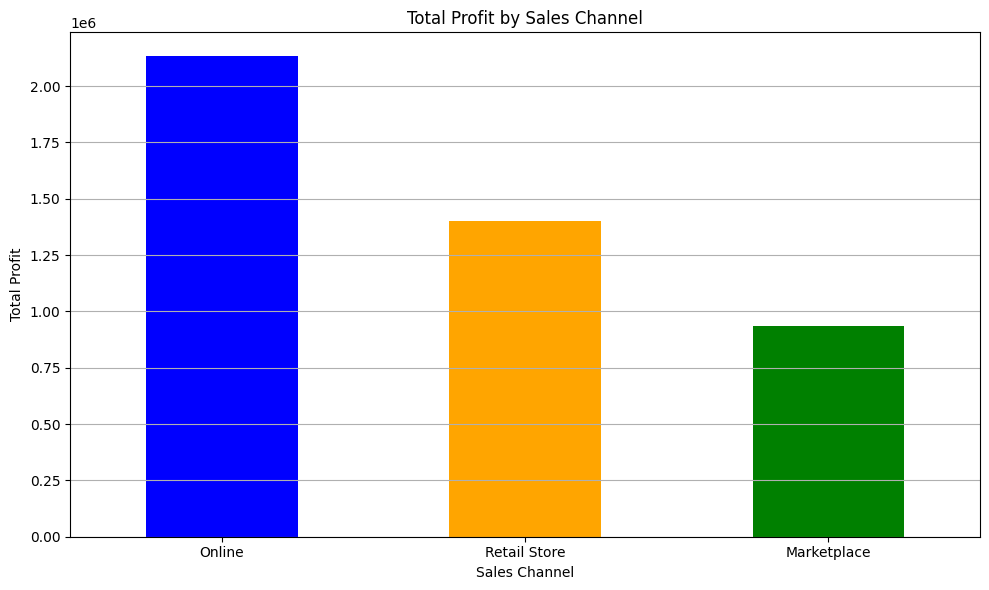

PROFIT BY SALES CHANNEL
Sales_Channel
Online          2132307.70
Retail Store    1400230.06
Marketplace      933783.23
Name: Profit, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

channel_profit = df.groupby('Sales_Channel')['Profit'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

channel_profit.plot(kind='bar', color=['blue', 'orange', 'green'])

plt.title('Total Profit by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

print("PROFIT BY SALES CHANNEL")
print(channel_profit)

<Figure size 1000x600 with 0 Axes>

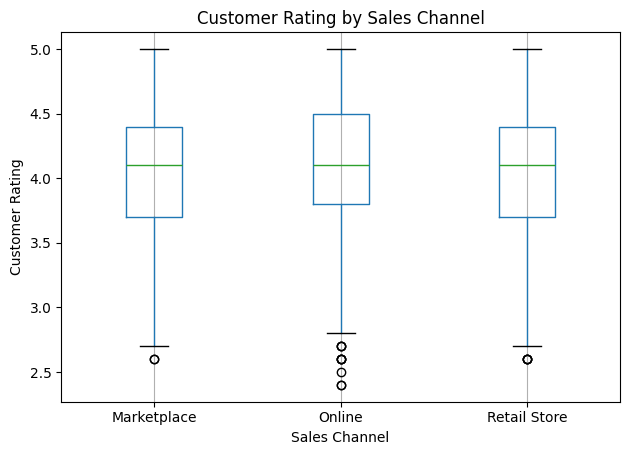

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

df.boxplot(
    column='Customer_Rating',
    by='Sales_Channel'
)

plt.title('Customer Rating by Sales Channel')
plt.suptitle('')
plt.xlabel('Sales Channel')
plt.ylabel('Customer Rating')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

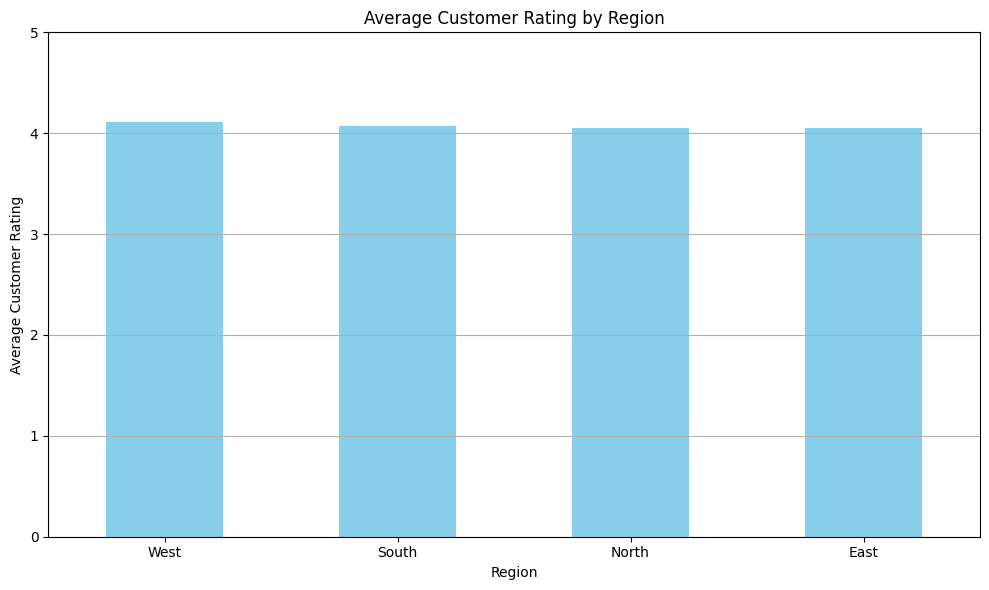

AVERAGE CUSTOMER RATING BY REGION
Region
West     4.11
South    4.07
North    4.05
East     4.05
Name: Customer_Rating, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

region_rating = df.groupby('Region')['Customer_Rating'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

region_rating.plot(kind='bar', color='skyblue')

plt.title('Average Customer Rating by Region')
plt.xlabel('Region')
plt.ylabel('Average Customer Rating')
plt.xticks(rotation=0)
plt.ylim(0, 5)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

print("AVERAGE CUSTOMER RATING BY REGION")
print(region_rating.round(2))

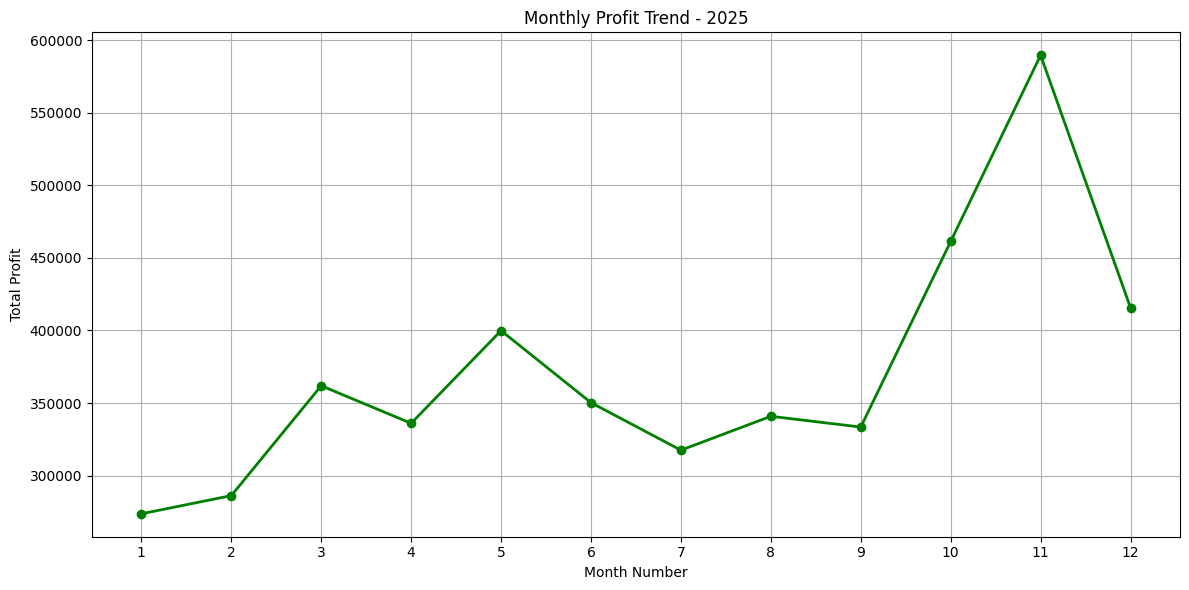

MONTHLY PROFIT
Month_Num
1     273727.58
2     286242.25
3     361905.34
4     336050.02
5     399865.90
6     350269.29
7     317539.76
8     340879.43
9     333456.74
10    461278.79
11    589519.45
12    415586.44
Name: Profit, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

monthly_profit = df.groupby('Month_Num')['Profit'].sum()

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_profit.index,
    monthly_profit.values,
    marker='o',
    color='green',
    linewidth=2
)

plt.title('Monthly Profit Trend - 2025')
plt.xlabel('Month Number')
plt.ylabel('Total Profit')
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

print("MONTHLY PROFIT")
print(monthly_profit)

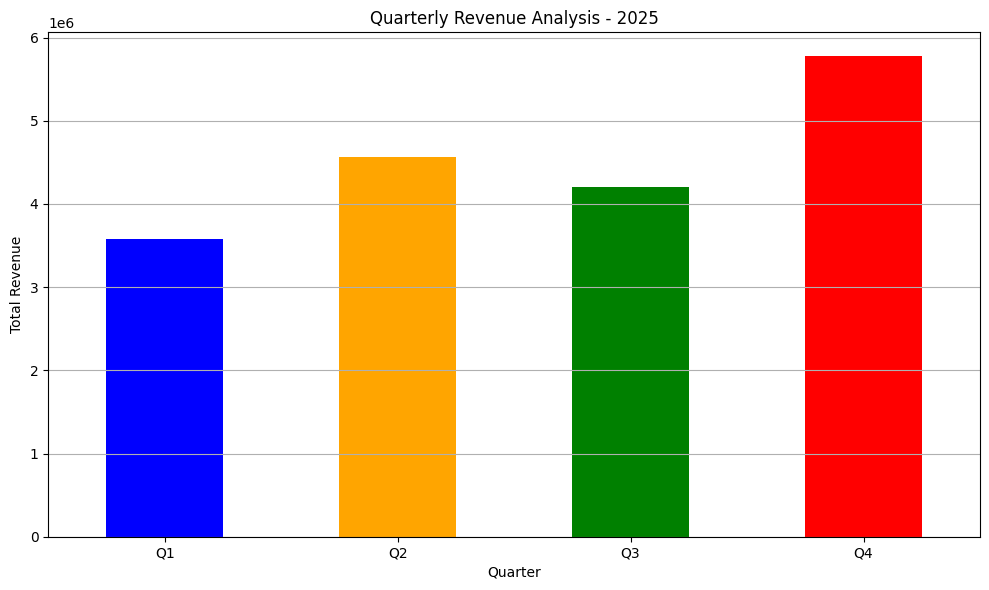

QUARTERLY REVENUE
Quarter
Q1    3577811.70
Q2    4559248.40
Q3    4207699.65
Q4    5773955.30
Name: Revenue, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

quarterly_revenue = df.groupby('Quarter')['Revenue'].sum()

plt.figure(figsize=(10, 6))

quarterly_revenue.plot(
    kind='bar',
    color=['blue', 'orange', 'green', 'red']
)

plt.title('Quarterly Revenue Analysis - 2025')
plt.xlabel('Quarter')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

print("QUARTERLY REVENUE")
print(quarterly_revenue)

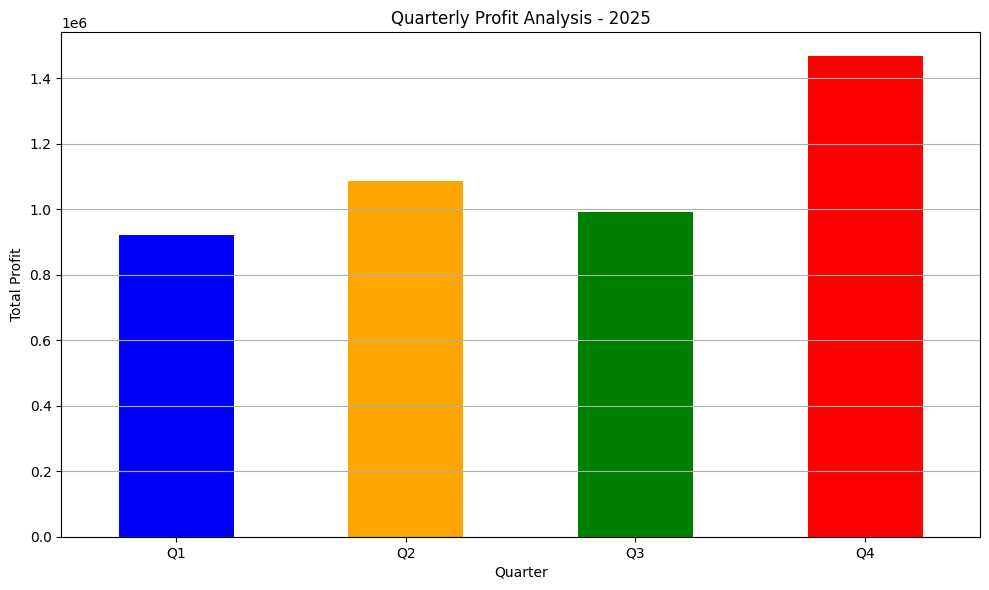

QUARTERLY PROFIT
Quarter
Q1     921875.17
Q2    1086185.21
Q3     991875.93
Q4    1466384.68
Name: Profit, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

quarterly_profit = df.groupby('Quarter')['Profit'].sum()

plt.figure(figsize=(10, 6))

quarterly_profit.plot(
    kind='bar',
    color=['blue', 'orange', 'green', 'red']
)

plt.title('Quarterly Profit Analysis - 2025')
plt.xlabel('Quarter')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

print("QUARTERLY PROFIT")
print(quarterly_profit)

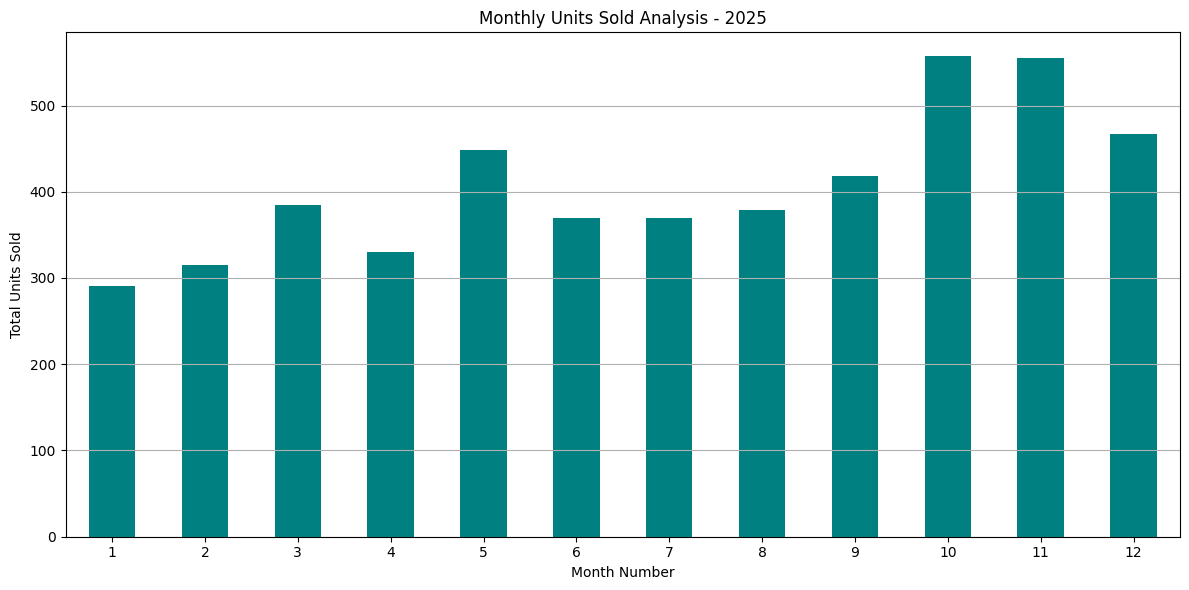

MONTHLY UNITS SOLD
Month_Num
1     291
2     315
3     385
4     330
5     448
6     370
7     369
8     379
9     418
10    557
11    555
12    467
Name: Units, dtype: int64


In [ ]:
monthly_units = df.groupby('Month_Num')['Units'].sum()

plt.figure(figsize=(12, 6))

monthly_units.plot(
    kind='bar',
    color='teal'
)

plt.title('Monthly Units Sold Analysis - 2025')
plt.xlabel('Month Number')
plt.ylabel('Total Units Sold')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

print("MONTHLY UNITS SOLD")
print(monthly_units)

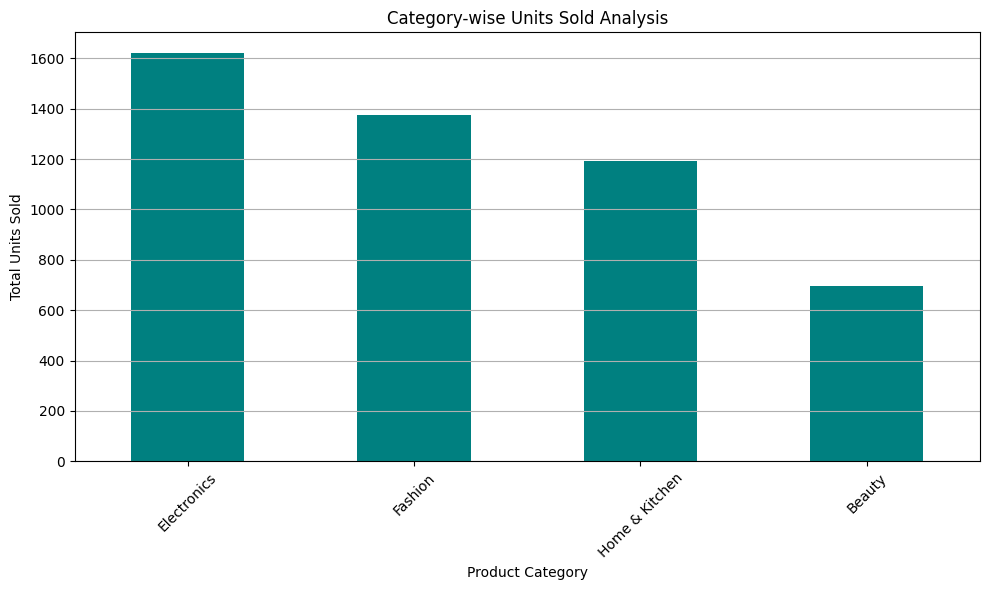

CATEGORY-WISE UNITS SOLD
Category
Electronics       1622
Fashion           1376
Home & Kitchen    1191
Beauty             695
Name: Units, dtype: int64


In [ ]:
category_units = df.groupby('Category')['Units'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

category_units.plot(
    kind='bar',
    color='teal'
)

plt.title('Category-wise Units Sold Analysis')
plt.xlabel('Product Category')
plt.ylabel('Total Units Sold')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

print("CATEGORY-WISE UNITS SOLD")
print(category_units)

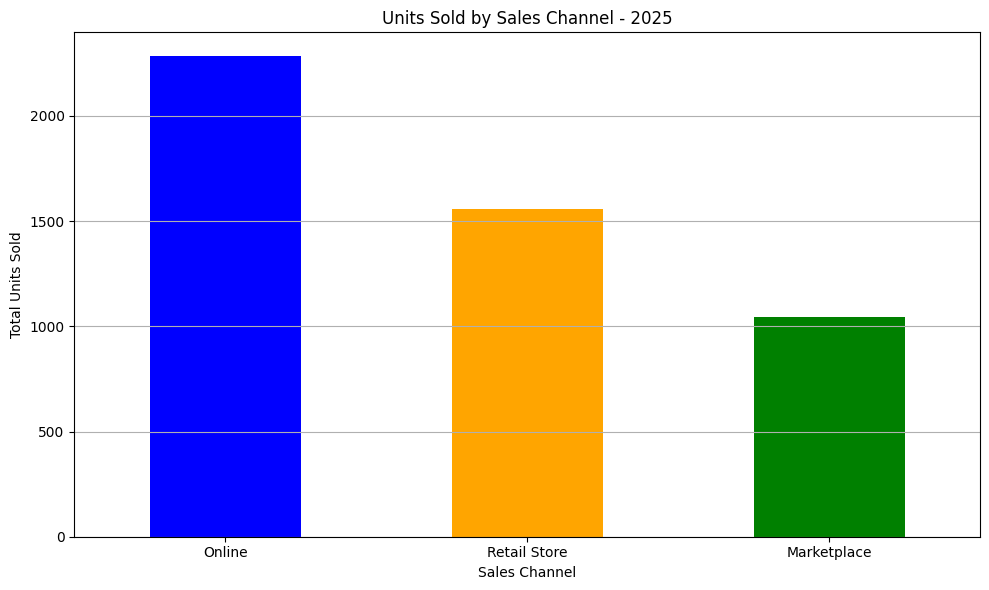

UNITS SOLD BY SALES CHANNEL
Sales_Channel
Online          2283
Retail Store    1557
Marketplace     1044
Name: Units, dtype: int64


In [ ]:
channel_units = df.groupby('Sales_Channel')['Units'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

channel_units.plot(
    kind='bar',
    color=['blue', 'orange', 'green']
)

plt.title('Units Sold by Sales Channel - 2025')
plt.xlabel('Sales Channel')
plt.ylabel('Total Units Sold')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

print("UNITS SOLD BY SALES CHANNEL")
print(channel_units)